In [3]:
# I import what I need
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# I walk up from this notebook's folder until I find the repo root (it has a "common" folder)
root = Path.cwd()
while not (root / "common").exists():
    root = root.parent

# I add the repo root to Python's search path so I can import common
sys.path.insert(0, str(root))

from common.io import load_parquet, DATA_DIR

# I load the parquet copy I saved
df = load_parquet(DATA_DIR / "processed" / "nf_unsw_nb15_v2.parquet")
print("shape:", df.shape)

# I count exact duplicate rows
print("duplicate rows:", df.duplicated().sum())

# I count missing values and infinite values in the numeric columns
print("missing values:", int(df.isna().sum().sum()))
numeric = df.select_dtypes(include=[np.number])
print("infinite values:", int(np.isinf(numeric).sum().sum()))

shape: (2390275, 45)
duplicate rows: 0
missing values: 0
infinite values: 0


In [3]:
# I look only at the attack flows
attacks = df[df["Label"] == 1]

# I count flows for each (attack class, source IP) pair, which is my candidate campaign
campaigns = attacks.groupby(["Attack", "IPV4_SRC_ADDR"]).size()

print("unique source IPs overall:", df["IPV4_SRC_ADDR"].nunique())
print("unique source IPs in attacks:", attacks["IPV4_SRC_ADDR"].nunique())
print("candidate campaigns:", len(campaigns))

# I summarise how many flows each candidate campaign has
print("\nflows per campaign:")
print(campaigns.describe())

# I count candidate campaigns per attack class
print("\ncampaigns per attack class:")
print(campaigns.groupby("Attack").size())

unique source IPs overall: 40
unique source IPs in attacks: 4
candidate campaigns: 36

flows per campaign:
count      36.000000
mean     2640.361111
std      2712.395190
min        29.000000
25%       362.750000
50%      1239.500000
75%      5034.250000
max      8602.000000
dtype: float64

campaigns per attack class:
Attack
Analysis          4
Backdoor          4
DoS               4
Exploits          4
Fuzzers           4
Generic           4
Reconnaissance    4
Shellcode         4
Worms             4
dtype: int64


In [4]:
# I count unique destination IPs overall and in attacks
print("unique destination IPs overall:", df["IPV4_DST_ADDR"].nunique())
print("unique destination IPs in attacks:", attacks["IPV4_DST_ADDR"].nunique())

# I count unique (source IP, destination IP) pairs overall and in attacks
pairs_all = df.groupby(["IPV4_SRC_ADDR", "IPV4_DST_ADDR"]).ngroups
pairs_attack = attacks.groupby(["IPV4_SRC_ADDR", "IPV4_DST_ADDR"]).ngroups
print("unique (src, dst) pairs overall:", pairs_all)
print("unique (src, dst) pairs in attacks:", pairs_attack)

# I count candidate campaigns if I add the destination IP to the definition
fine = attacks.groupby(["Attack", "IPV4_SRC_ADDR", "IPV4_DST_ADDR"]).size()
print("\ncampaigns with (class, src, dst):", len(fine))
print(fine.describe())

# I show the 4 attacker IPs and how many attack flows each sends
print("\nattack flows per attacker IP:")
print(attacks["IPV4_SRC_ADDR"].value_counts())

unique destination IPs overall: 40
unique destination IPs in attacks: 10
unique (src, dst) pairs overall: 293
unique (src, dst) pairs in attacks: 40

campaigns with (class, src, dst): 345
count     345.000000
mean      275.515942
std       355.164285
min         1.000000
25%        25.000000
50%       103.000000
75%       397.000000
max      2063.000000
dtype: float64

attack flows per attacker IP:
IPV4_SRC_ADDR
175.45.176.1    27505
175.45.176.0    25745
175.45.176.3    23030
175.45.176.2    18773
Name: count, dtype: int64


In [5]:
# I import the tools I need for this check
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

# I take a 300,000 row sample so the check runs quickly
sample = df.sample(n=300_000, random_state=0)

# I list the columns I never use as features (IPs, source port, labels)
excluded = ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "Label", "Attack"]
features = [c for c in df.columns if c not in excluded]

# I split the sample once, keeping the attack share the same in both parts
train, test = train_test_split(sample, test_size=0.3, random_state=0, stratify=sample["Label"])

# I train a tiny tree on each single column and measure how well it ranks attacks
rows = []
for col in features:
    tree = DecisionTreeClassifier(max_depth=3, random_state=0)
    tree.fit(train[[col]], train["Label"])
    scores = tree.predict_proba(test[[col]])[:, 1]
    rows.append((col, roc_auc_score(test["Label"], scores)))

# I show the columns with the highest single-column AUC first
result = pd.DataFrame(rows, columns=["column", "single_column_auc"])
print(result.sort_values("single_column_auc", ascending=False).head(12).to_string(index=False))

# I take a direct look at DNS_QUERY_ID
print("\nunique DNS_QUERY_ID values:", df["DNS_QUERY_ID"].nunique())
print("\nDNS_QUERY_ID == 0 share, by label:")
print((df["DNS_QUERY_ID"] == 0).groupby(df["Label"]).mean())

                  column  single_column_auc
                 MAX_TTL           0.997090
                 MIN_TTL           0.996609
          MIN_IP_PKT_LEN           0.993082
       SHORTEST_FLOW_PKT           0.971489
         TCP_WIN_MAX_OUT           0.953080
          TCP_WIN_MAX_IN           0.947047
        SERVER_TCP_FLAGS           0.923380
                OUT_PKTS           0.881768
NUM_PKTS_UP_TO_128_BYTES           0.876102
 DST_TO_SRC_SECOND_BYTES           0.852350
 SRC_TO_DST_SECOND_BYTES           0.845584
               OUT_BYTES           0.838644

unique DNS_QUERY_ID values: 64243

DNS_QUERY_ID == 0 share, by label:
Label
0    0.843608
1    0.879741
Name: DNS_QUERY_ID, dtype: float64


In [6]:
# I look at the most common MAX_TTL values for benign flows and for attack flows
for label, name in [(0, "benign"), (1, "attack")]:
    part = df[df["Label"] == label]
    print(f"MAX_TTL, {name} flows (share of that class):")
    print(part["MAX_TTL"].value_counts(normalize=True).head(6).round(4))
    print()

# I check how the attack classes differ in MAX_TTL
print("share of each attack class with MAX_TTL == 254:")
print((df["MAX_TTL"] == 254).groupby(df["Attack"]).mean().round(3))

MAX_TTL, benign flows (share of that class):
MAX_TTL
32     0.8325
31     0.1514
0      0.0052
255    0.0039
63     0.0029
30     0.0022
Name: proportion, dtype: float64

MAX_TTL, attack flows (share of that class):
MAX_TTL
255    0.3792
254    0.3678
63     0.2476
62     0.0032
0      0.0022
Name: proportion, dtype: float64

share of each attack class with MAX_TTL == 254:
Attack
Analysis          0.798
Backdoor          0.776
Benign            0.001
DoS               0.385
Exploits          0.076
Fuzzers           0.296
Generic           0.807
Reconnaissance    0.479
Shellcode         0.502
Worms             0.128
Name: MAX_TTL, dtype: float64


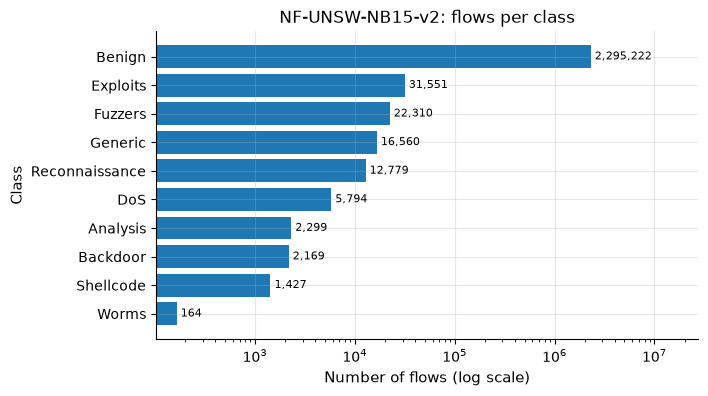

In [7]:
# I import my shared plotting helpers and matplotlib
import matplotlib.pyplot as plt

from common.plotting import set_style, save_figure

set_style()

# I count flows per class, largest first
counts = df["Attack"].value_counts()

# I draw a horizontal bar chart on a log axis so small classes stay visible
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(counts.index[::-1], counts.values[::-1])
ax.set_xscale("log")
ax.set_xlabel("Number of flows (log scale)")
ax.set_ylabel("Class")
ax.set_title("NF-UNSW-NB15-v2: flows per class")

# I write each count at the end of its bar
for i, value in enumerate(counts.values[::-1]):
    ax.text(value * 1.1, i, f"{value:,}", va="center", fontsize=8)

# I leave room on the right so the labels fit
ax.set_xlim(right=counts.max() * 12)

# I save the figure as PNG and PDF in the project results folder
out = root / "p1_monitoring_budget" / "results" / "eda_class_balance"
save_figure(fig, out)
plt.show()

time columns: []
                   feature  class   q25  median     q75
                  IN_BYTES benign 481.0  1684.0  3302.0
                  IN_BYTES attack 200.0   570.0  1114.0
                 OUT_BYTES benign 320.0  2512.0 15236.0
                 OUT_BYTES attack   0.0   256.0   786.0
                   IN_PKTS benign   5.0    19.0    44.0
                   IN_PKTS attack   2.0    10.0    12.0
                  OUT_PKTS benign   4.0    18.0    45.0
                  OUT_PKTS attack   0.0     6.0    10.0
FLOW_DURATION_MILLISECONDS benign   0.0     0.0     0.0
FLOW_DURATION_MILLISECONDS attack   0.0     0.0     0.0


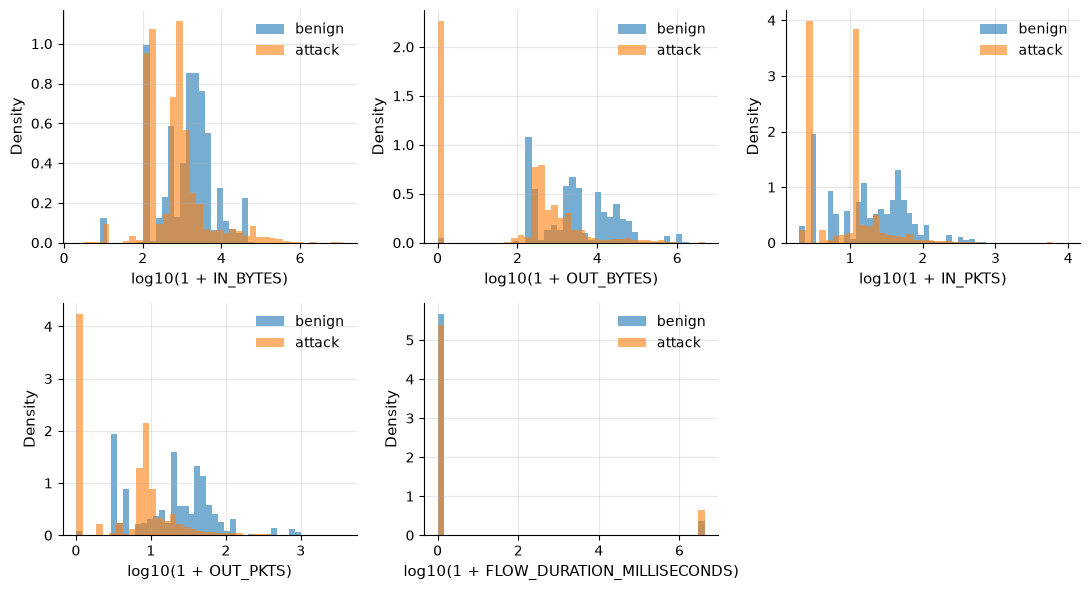

In [4]:
import matplotlib.pyplot as plt

from common.plotting import set_style, save_figure

set_style()

# Look for any time column
time_cols = [c for c in df.columns if "TIME" in c.upper() or "DATE" in c.upper()]
print("time columns:", time_cols)

# Features to look at
features = ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS", "FLOW_DURATION_MILLISECONDS"]

# Quartiles for benign and attack flows
rows = []
for name in features:
    for label, group in [("benign", df[df["Label"] == 0]), ("attack", df[df["Label"] == 1])]:
        q = group[name].quantile([0.25, 0.5, 0.75])
        rows.append((name, label, q[0.25], q[0.5], q[0.75]))
table = pd.DataFrame(rows, columns=["feature", "class", "q25", "median", "q75"])
print(table.to_string(index=False))

# Use a sample so the plot is fast
sample = df.sample(n=200_000, random_state=0)

# One small plot per feature
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
axes = axes.flatten()

for ax, name in zip(axes, features):
    # Log scale makes the big range easy to read
    benign = np.log10(1 + sample.loc[sample["Label"] == 0, name])
    attack = np.log10(1 + sample.loc[sample["Label"] == 1, name])
    ax.hist(benign, bins=40, alpha=0.6, density=True, label="benign")
    ax.hist(attack, bins=40, alpha=0.6, density=True, label="attack")
    ax.set_xlabel(f"log10(1 + {name})")
    ax.set_ylabel("Density")
    ax.legend()

# Hide the empty last plot
axes[-1].axis("off")

# Save as PNG and PDF
fig.tight_layout()
save_figure(fig, root / "p1_monitoring_budget" / "results" / "eda_feature_distributions")
plt.show()

In [ ]:
from common.io import save_csv

# Count flows that return no bytes and flows with duration 0, for each class
rows = []
for name, group in df.groupby("Attack"):
    rows.append({
        "class": name,
        "flows": len(group),
        "zero_out_bytes": int((group["OUT_BYTES"] == 0).sum()),
        "zero_duration": int((group["FLOW_DURATION_MILLISECONDS"] == 0).sum()),
    })
check = pd.DataFrame(rows)

# Share of flows in each class
check["zero_out_share"] = (check["zero_out_bytes"] / check["flows"]).round(3)
check["zero_duration_share"] = (check["zero_duration"] / check["flows"]).round(3)
print(check.to_string(index=False))

# Save the counts
save_csv(check, root / "p1_monitoring_budget" / "results" / "label_check.csv")